# S04 · 三个定义：干热、夜热、湿热

> **Day 4 / 14** ｜ 对应论文章节 **3.4 + 3.5（Hazard definitions）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 从人体热平衡出发，解释为什么「气温」不足以描述热危险
- 手算并验证 Stull (2011) 湿球公式
- 说清楚为什么第三定义用 **Twmax**，而不是 Twmin 或 Twmean
- 让三套定义并行跑通，并看懂它们之间的一致性与分歧

---

## 1. 为什么需要湿球

人体靠**出汗蒸发**散热。散热的速率取决于空气还能「容纳」多少水汽 —— 这正是湿球温度（wet-bulb temperature, `Tw`）度量的东西。

```
Tw 高  →  汗蒸发不掉  →  体温上升  →  热射病
Tw 低  →  汗能蒸发    →  体温可控
```

- **Sherwood & Huber (2010)**：理论极限约 **35 °C**（皮肤表面饱和，汗液无法蒸发）
- **Vecellio et al. (2022)**：实测临界值 **30.55 ± 0.98 °C**，显著低于 35 °C

> 📌 这是你论文里可以写的一句话：**「35 °C 是理论值，30.6 °C 是实测值，两者都不能直接套用到日尺度统计上 —— 但它们共同说明：只看气温会低估湿热危险。」**

---

## 2. Stull (2011) 公式与验算

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
ex <- data.frame(
  scenario = c("湿热午后", "干热午后", "标准校验点", "闷热傍晚"),
  T  = c(33, 40, 30, 35),
  RH = c(85, 15, 50, 70)
)
ex$Tw          <- round(stull_tw(ex$T, ex$RH), 2)
ex$depression  <- round(ex$T - ex$Tw, 2)
print(ex, row.names = FALSE)

   scenario  T RH    Tw depression
   湿热午后 33 85 30.80       2.20
   干热午后 40 15 20.77      19.23
 标准校验点 30 50 22.30       7.70
   闷热傍晚 35 70 30.25       4.75


> 🔍 **看前两行**：40 °C 的干热，湿球只有约 21 °C；33 °C 的湿热，湿球却接近 31 °C。
> **气温更高，危险更低。** 这就是「只看气温会误判」的具体数字。

In [3]:
# 标准校验：Stull (2011) 论文给出的样例 T=30, RH=50 -> Tw ≈ 22.3
cat("T=30, RH=50 -> Tw =", round(stull_tw(30, 50), 2), "degC\n")

T=30, RH=50 -> Tw = 22.3 degC


---

## 3. 物理约束：Tw 永远 ≤ T

In [4]:
d <- load_clean_daily()

viol <- d %>% filter(!is.na(twmax), !is.na(tmax)) %>%
  mutate(bad = twmax > tmax + 0.05) %>% summarise(n = sum(bad)) %>% pull(n)

cat("全数据 Twmax > Tmax 的日数:", viol, " (应为 0)\n")

全数据 Twmax > Tmax 的日数: 0  (应为 0)


In [5]:
# 湿球相对干球的"亏损"有多大？这决定了 Tw 序列和 T 序列有多不同
d %>%
  filter(!is.na(twmax)) %>%
  mutate(dep = tmax - twmax) %>%
  summarise(min = min(dep), q25 = quantile(dep, .25), median = median(dep),
            q75 = quantile(dep, .75), max = max(dep)) %>%
  print()

         min     q25   median      q75      max
1 0.02550706 2.05097 2.508362 2.978851 6.120544


> 📌 亏损的中位数决定了 Tw 阈值比 Tmax 阈值低多少度。马来西亚通常在 **2–5 °C**。
> 这个数字要写进论文的 Data 节，让读者知道两个定义不是「差不多」。

---

## 4. 三定义并行

In [6]:
STATION <- "Kuantan"
s <- d %>% filter(station == STATION) %>% arrange(date)
s <- s[format(s$date, "%m-%d") != "02-29", ]

doy <- as.integer(format(s$date, "%j"))
yr  <- as.integer(format(s$date, "%Y"))

ev_list <- lapply(DEFS, function(dn) {
  e <- extract_events(s, VAR_OF[[dn]], defn = dn)
  if (!is.null(e)) {
    e$mean_value <- NA_real_     # 占位，下面统一补
    e
  }
})
ev_list <- Filter(Negate(is.null), ev_list)
ev <- do.call(rbind, ev_list)

cat("事件数：\n"); print(table(ev$defn))

事件数：



 Tmax  Tmin Twmax 
   90    44    82 


In [7]:
ev %>%
  group_by(defn) %>%
  summarise(n = n(),
            median_duration = median(duration),
            max_duration    = max(duration),
            median_intensity = round(median(intensity), 2),
            max_intensity    = round(max(intensity), 2),
            .groups = "drop") %>%
  print()

# A tibble: 3 × 6
  defn      n median_duration max_duration median_intensity max_intensity
  <chr> <int>           <dbl>        <dbl>            <dbl>         <dbl>
1 Tmax     90               4           13             1.55          3.6 
2 Tmin     44               4            6             1.9           4.7 
3 Twmax    82               4           11             1.64          3.83


---

## 5. 三套定义什么时候一致？什么时候分歧？

In [8]:
ex_days <- sapply(DEFS, function(dn) {
  v  <- s[[VAR_OF[[dn]]]]
  th <- daily_threshold(doy, v, yr)
  as.integer(v > th[doy])
})
colnames(ex_days) <- DEFS

cat("各定义下的超阈值日数：\n"); print(colSums(ex_days, na.rm = TRUE))
cat("\n日均一致性（Jaccard）：\n")
jaccard <- function(a, b) sum(a & b, na.rm = TRUE) / sum(a | b, na.rm = TRUE)
print(round(outer(DEFS, DEFS, Vectorize(function(a, b)
  jaccard(ex_days[, a], ex_days[, b]))), 3))

各定义下的超阈值日数：


 Tmax  Tmin Twmax 
 1519  1557  1604 



日均一致性（Jaccard）：


      [,1]  [,2]  [,3]
[1,] 1.000 0.427 0.542
[2,] 0.427 1.000 0.354
[3,] 0.542 0.354 1.000


> 🔍 **如果三套定义的 Jaccard 只有 0.2–0.4，说明它们识别的是不同的危险。**
> 这正是整篇论文的立论基础 —— 如果三套定义几乎一样，多定义设计就没有意义。

---

## 6. 事件属性的分布对比

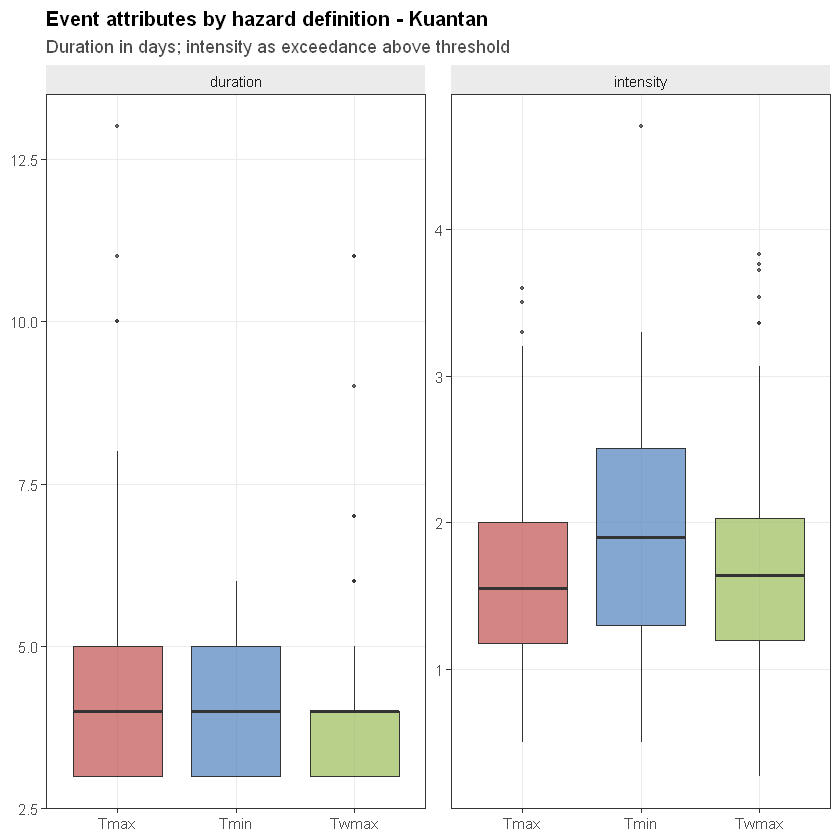

In [9]:
# 用列索引而不是 select()：多个包都有同名函数，容易遮蔽
ev_long <- tidyr::pivot_longer(
  ev[, c("defn", "duration", "intensity")],
  c(duration, intensity),
  names_to = "attribute", values_to = "value"
)

p_def <- ggplot(ev_long, aes(defn, value, fill = defn)) +
  geom_boxplot(alpha = 0.7, outlier.size = 0.8) +
  facet_wrap(~attribute, scales = "free_y") +
  scale_fill_manual(values = c(Tmax = "#C0504D", Tmin = "#4F81BD", Twmax = "#9BBB59")) +
  labs(x = NULL, y = NULL,
       title = paste("Event attributes by hazard definition -", STATION),
       subtitle = "Duration in days; intensity as exceedance above threshold") +
  theme_paper() + theme(legend.position = "none")

save_fig(p_def, "S04_definition_attributes", 7, 4)
p_def

---

## 7. 为什么不用 Twmin 和 Twmean

| 选项 | 是否采用 | 理由 |
|---|---|---|
| **Twmax** | ✅ 主分析 | 与 Tmax 严格平行；代表白天峰值热应激；Raymond et al. (2020)、Im et al. (2017) 均如此 |
| Twmin | ❌ | 热带清晨相对湿度常达 95–99%，接近饱和 → **`Twmin ≈ Tmin`**，与 Tmin 定义高度共线，不提供新信息 |
| Twmean | ⚠️ 附录 | 只在讨论生理阈值时需要（Vecellio 的 30.55 °C 是稳态值，与日均值更可比），不作为主定义 |

In [10]:
# 验证 "Twmin ≈ Tmin" 这个论断
# 用 Tmin 与 RH 估一个夜间湿球（清晨近似饱和）
s$tw_night_approx <- stull_tw(s$tmin, pmin(s$rh + 8, 99))
cat("cor(Tmin, Tw_night_approx) =",
    round(cor(s$tmin, s$tw_night_approx, use = "complete.obs"), 3), "\n")
cat("平均差 =", round(mean(s$tw_night_approx - s$tmin, na.rm = TRUE), 2), "degC\n")

cor(Tmin, Tw_night_approx) = 0.95 


平均差 = -1.21 degC


> 📌 相关系数若在 0.95 以上，说明 **TN90p 本质上已经是一个夜间湿球指数**。
> 这句话可以直接写进方法章，用来回应「你没有湿度数据就没法做湿热」的质疑。

---

## 8. 关于真实数据的采购（重要）

本手册用 `stull_tw(tmax, rh)` 近似 Twmax，因为模拟数据只有日均 `rh`。

**真实研究里不要这样做。** MetMalaysia 直接出售：

> **`Daily Maximum Wet Bulb Temperature`**（每日最高湿球温度）

直接购买它有三个好处：

1. 用本站气压计算 → Cameron Highlands（1545 m）不会因海平面公式而偏差
2. 是当日所有观测的最大值 → 正是 Twmax 的定义
3. 免去「用日均 RH 配 Tmax」造成的高估（通常 1–2 °C）

真数据到位后，只需在 `00_setup.R` 的 `read_raw_station()` 里加一列映射：

In [11]:
# 伪代码：真数据列名映射示例
# df$twmax <- df$daily_max_wet_bulb

---

## 9. 本讲产出

In [12]:
cat("产出：\n")
cat(" ", file.path(PATHS$mfig, "S04_definition_attributes.png"), "\n")

产出：


  C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S04_definition_attributes.png 


---

## 10. 常见错误

| 错误 | 后果 |
|---|---|
| 用 RH 0–1 代入 Stull 公式 | Tw 完全错误（可能 > T） |
| 用日均 RH 配 Tmax 算 Twmax | 系统性高估 1–2 °C |
| 把 Twmin 当成第三个独立定义 | 与 Tmin 高度共线，RDI 接近 0，白占格子 |
| 三个定义用不同的阈值参数 | 比较失去意义 |
| 忘记报告 Tw 与 T 的平均亏损 | 读者无法判断两个定义差多少 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 40 °C / 15% RH 的湿球只有约 21 °C？</summary>

因为空气很干，水蒸发得快，能一直把温度拉低到接近露点。干空气的「蒸发冷却潜力」很大，所以湿球远低于干球。
</details>

<details>
<summary>Q2：如果 Twmax 的 90 百分位阈值是 28 °C，而 Vecellio 的实测临界是 30.55 °C，说明什么？</summary>

说明该站的极端湿热**尚未达到**人体耐受临界。但要注意口径不同：28 °C 是日峰值，30.55 °C 是稳态暴露。论文里应明确这一点，不做定量外推。
</details>

<details>
<summary>Q3：为什么三套定义的 Jaccard 距离很重要？</summary>

如果三套定义识别的事件几乎相同，那么「多定义」就是冗余设计，RDI 会接近 0，论文的核心论点不成立。Jaccard 在 0.2–0.5 之间才说明「用哪个定义真的会改变结论」。
</details>

<details>
<summary>Q4：Cameron Highlands 用 Stull 公式会有什么问题？</summary>

Stull 公式在 101.325 kPa 下标定。1545 m 处气压约 840 hPa，湿球温度会偏高零点几度。对 90 百分位阈值来说不可忽略。必须用考虑气压的算法（Davies-Jones）或直接购买 MetMalaysia 的 Tw 产品。
</details>

---

## 下一步

**S05 · 事件目录（RO1 完成）**：把三套定义 × 10 个站全部跑一遍，做出论文 Table 1。